# 06 — Interpretación del modelo final
[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/AlejandroP212/ML2-Proyecto-Riesgo-Crediticio/blob/main/notebooks/06_interpretacion.ipynb)

**Integrantes:** David Castro & Alejandro Pardo
**Asignatura:** Machine Learning II — Universidad Externado de Colombia

Corresponde a la sección **8.2 Interpretación de resultados** de la Entrega final. Se interpreta el modelo final
(Regresión Logística, notebook 05) con tres herramientas complementarias:

| Pregunta | Herramienta | Sección |
|---|---|---|
| ¿Qué variables aumentan o reducen el riesgo, y cuánto? ¿Son estables esas estimaciones? | Coeficientes como *odds ratios* con intervalos bootstrap | 1 |
| ¿Qué variables pesan más en el conjunto de solicitantes? | SHAP global | 2 |
| ¿Por qué el modelo decidió así con un solicitante concreto? | SHAP local | 3 |
| ¿Cómo cambia la probabilidad de mora al mover una variable? | Dependencia parcial (PDP) e ICE | 4 |
| ¿Quiénes son los errores del modelo y qué implican? | Perfil de errores | 5 |

In [1]:
# === Configuración de rutas (funciona en Colab y en local) ===
import os, sys
from pathlib import Path

if "google.colab" in sys.modules and not Path("ML2-Proyecto-Riesgo-Crediticio").exists():
    !git clone -q https://github.com/AlejandroP212/ML2-Proyecto-Riesgo-Crediticio.git
    os.chdir("ML2-Proyecto-Riesgo-Crediticio")
    !pip install -q shap==0.54.1

ROOT = Path.cwd()
while not (ROOT / "CHECKSUMS.txt").exists() and ROOT != ROOT.parent:
    ROOT = ROOT.parent
sys.path.insert(0, str(ROOT))
DATA, FIGS, TABLES, MODELS = ROOT / "data", ROOT / "figuras", ROOT / "resultados", ROOT / "modelos"
for d in (DATA, FIGS, TABLES):
    d.mkdir(exist_ok=True)
SEED = 42
print("Raíz del proyecto encontrada:", ROOT.name)

Raíz del proyecto encontrada: ml2-proyecto-riesgo-crediticio


In [2]:
import json, warnings
warnings.filterwarnings("ignore", message="IProgress not found")
warnings.filterwarnings("ignore", message="X has feature names")
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import joblib
import shap
from shap.plots._labels import labels as etiquetas_shap
etiquetas_shap.update({"FEATURE_VALUE": "Valor de la variable", "FEATURE_VALUE_LOW": "Bajo", "FEATURE_VALUE_HIGH": "Alto"})
from sklearn.model_selection import train_test_split
from sklearn.base import clone

plt.style.use("seaborn-v0_8-whitegrid")
ruta = DATA / "credito_colombia_simulado.csv"
if not ruta.exists():  # si no se ejecutó el notebook 01, se genera aquí
    from src.simulacion_credito import generar_dataset_credito_colombia
    generar_dataset_credito_colombia(6000, SEED).to_csv(ruta, index=False)
df = pd.read_csv(ruta)
X, y = df.drop(columns="incumple"), df["incumple"]
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.20, random_state=SEED, stratify=y)

modelo = joblib.load(MODELS / "modelo_final.joblib")
meta = json.loads((MODELS / "modelo_final_metadata.json").read_text(encoding="utf-8"))
UMBRAL, PRIOR = meta["umbral_decision"], meta["prior_mora_entrenamiento"]
preproc, lr = modelo[:-1], modelo[-1]

def prob_corregida(p, prior=PRIOR):
    odds = p / (1 - p) * prior / (1 - prior)
    return odds / (1 + odds)

NOMBRES = {"edad": "Edad", "es_informal": "Empleo informal", "antiguedad_laboral": "Antigüedad laboral (años)",
           "ingreso_smmlv": "Ingreso (SMMLV)", "monto_credito_smmlv": "Monto del crédito (SMMLV)",
           "plazo_meses": "Plazo (meses)", "creditos_activos": "Créditos activos", "moras_previas": "Moras previas",
           "score_crediticio": "Score crediticio", "relacion_cuota_ingreso": "Relación cuota/ingreso"}
print(f"Modelo: {meta['modelo']} | C = {meta['hiperparametros']['C']} | umbral = {UMBRAL}")

Modelo: Regresión Logística (class_weight='balanced') en Pipeline: SimpleImputer(median) -> StandardScaler | C = 0.1 | umbral = 0.44


## 1. Coeficientes como *odds ratios*
En una Regresión Logística cada coeficiente indica cuánto cambian las **odds de mora** (probabilidad de mora /
probabilidad de pagar) cuando la variable aumenta. Como el Pipeline estandariza las variables, el coeficiente aprendido
corresponde a **una desviación estándar** de la variable; se reporta también por unidad natural (un año, un SMMLV, una
mora, un punto de score).

La **estabilidad** se mide con *bootstrap*: el modelo se reentrena 300 veces con muestras con reemplazo del
entrenamiento y se reporta el intervalo del 95 % de cada *odds ratio*. Un intervalo que no cruza 1 indica un efecto
estable en dirección.

In [3]:
escala = pd.Series(preproc[-1].scale_, index=X.columns)
coef = pd.Series(lr.coef_[0], index=X.columns)

rng = np.random.default_rng(SEED)
boot = []
for _ in range(300):
    idx = rng.integers(0, len(X_train), len(X_train))
    m = clone(modelo).fit(X_train.iloc[idx], y_train.iloc[idx])
    boot.append(m[-1].coef_[0])
boot = pd.DataFrame(boot, columns=X.columns)

sim = {"es_informal": 0.80, "relacion_cuota_ingreso": 1.30, "antiguedad_laboral": -0.10, "score_crediticio": -0.007,
       "moras_previas": 0.50, "ingreso_smmlv": -0.12, "edad": 0.0, "plazo_meses": 0.0, "monto_credito_smmlv": 0.0,
       "creditos_activos": 0.0}
tabla_or = pd.DataFrame({
    "Variable": [NOMBRES[c] for c in X.columns],
    "OR por 1 desv. est.": np.exp(coef),
    "IC 95 % inferior": np.exp(boot.quantile(0.025)),
    "IC 95 % superior": np.exp(boot.quantile(0.975)),
    "Desv. est. de la variable": escala,
    "OR por unidad natural": np.exp(coef / escala),
    "Coef. por unidad (modelo)": coef / escala,
    "Coef. en la simulación": pd.Series(sim),
}, index=X.columns)
tabla_or["Cruza 1"] = (tabla_or["IC 95 % inferior"] < 1) & (tabla_or["IC 95 % superior"] > 1)
tabla_or = tabla_or.sort_values("OR por 1 desv. est.")
tabla_or.round(4).to_csv(TABLES / "tabla7_odds_ratios.csv")
tabla_or.round(4)

,Variable,OR por 1 desv. est.,IC 95 % inferior,IC 95 % superior,Desv. est. de la variable,OR por unidad natural,Coef. por unidad (modelo),Coef. en la simulación,Cruza 1
score_crediticio,Score crediticio,0.1283,0.0980,0.1586,83.0333,0.9756,-0.0247,-0.007,False
antiguedad_laboral,Antigüedad laboral (años),0.2097,0.1439,0.2932,4.2891,0.6948,-0.3642,-0.100,False
ingreso_smmlv,Ingreso (SMMLV),0.5358,0.3881,0.7129,1.6110,0.6788,-0.3874,-0.120,False
plazo_meses,Plazo (meses),0.8858,0.6960,1.1289,17.0576,0.9929,-0.0071,0.000,True
creditos_activos,Créditos activos,0.9504,0.8225,1.1036,1.1752,0.9576,-0.0433,0.000,True
edad,Edad,1.0240,0.8637,1.1975,14.9243,1.0016,0.0016,0.000,True
monto_credito_smmlv,Monto del crédito (SMMLV),1.1045,0.8909,1.3384,3.7118,1.0271,0.0268,0.000,True
relacion_cuota_ingreso,Relación cuota/ingreso,1.7594,1.4775,2.1502,0.1421,53.2595,3.9752,1.300,False
es_informal,Empleo informal,3.2420,2.7719,3.8125,0.4959,10.7158,2.3717,0.800,False
moras_previas,Moras previas,4.1025,3.6766,4.8710,0.7647,6.3348,1.8461,0.500,False


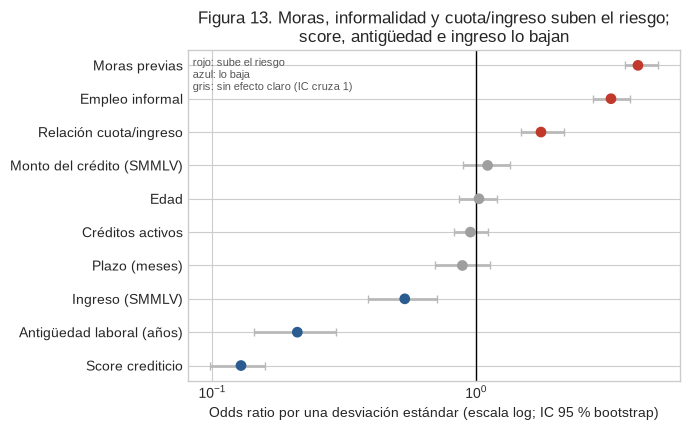

In [4]:
fig, ax = plt.subplots(figsize=(7, 4.4))
t = tabla_or
colores = np.where(t["Cruza 1"], "#9e9e9e", np.where(t["OR por 1 desv. est."] > 1, "#c0392b", "#2b5c8f"))
ax.errorbar(t["OR por 1 desv. est."], t["Variable"],
            xerr=[t["OR por 1 desv. est."] - t["IC 95 % inferior"], t["IC 95 % superior"] - t["OR por 1 desv. est."]],
            fmt="none", ecolor="#b9b9b9", elinewidth=2, capsize=3)
ax.scatter(t["OR por 1 desv. est."], t["Variable"], c=colores, s=45, zorder=3)
ax.axvline(1, color="black", lw=1)
ax.set_xscale("log")
ax.set(xlabel="Odds ratio por una desviación estándar (escala log; IC 95 % bootstrap)",
       title="Figura 13. Moras, informalidad y cuota/ingreso suben el riesgo;\nscore, antigüedad e ingreso lo bajan")
ax.text(0.01, 0.98, "rojo: sube el riesgo\nazul: lo baja\ngris: sin efecto claro (IC cruza 1)", transform=ax.transAxes,
        ha="left", va="top", fontsize=8, color="#555555")
plt.tight_layout(); plt.savefig(FIGS / "fig13_odds_ratios.png", dpi=300); plt.show()

In [5]:
# ¿El modelo recupera la estructura de la simulación? Proporción coeficiente del modelo / coeficiente simulado
recup = tabla_or.loc[[c for c in sim if sim[c] != 0], ["Variable", "Coef. por unidad (modelo)", "Coef. en la simulación"]].copy()
recup["Modelo / simulación"] = recup["Coef. por unidad (modelo)"] / recup["Coef. en la simulación"]
recup.round(4)

,Variable,Coef. por unidad (modelo),Coef. en la simulación,Modelo / simulación
es_informal,Empleo informal,2.3717,0.800,2.9646
relacion_cuota_ingreso,Relación cuota/ingreso,3.9752,1.300,3.0578
antiguedad_laboral,Antigüedad laboral (años),-0.3642,-0.100,3.6418
score_crediticio,Score crediticio,-0.0247,-0.007,3.5332
moras_previas,Moras previas,1.8461,0.500,3.6921
ingreso_smmlv,Ingreso (SMMLV),-0.3874,-0.120,3.2280


## 2. SHAP global
SHAP reparte la predicción de cada solicitante entre sus variables. Para una Regresión Logística el cálculo es **exacto**
(`LinearExplainer`): la contribución de una variable es su coeficiente por la distancia del solicitante al promedio, en
escala de log-odds. Se verifica que la suma de contribuciones reproduce la predicción del modelo.

In [6]:
Z_train = pd.DataFrame(preproc.transform(X_train), columns=X.columns)
Z_test = pd.DataFrame(preproc.transform(X_test), columns=X.columns)
explicador = shap.LinearExplainer(lr, shap.maskers.Independent(Z_train, max_samples=len(Z_train)))
sv = explicador(Z_test)
sv.data = X_test.values                      # mostrar los valores originales (no estandarizados) en los gráficos
sv.feature_names = [NOMBRES[c] for c in X.columns]
error = np.abs(sv.values.sum(1) + sv.base_values - lr.decision_function(Z_test)).max()
print(f"Error máximo de reconstrucción (log-odds): {error:.1e}")

imp_shap = pd.Series(np.abs(sv.values).mean(0), index=sv.feature_names).sort_values(ascending=False)
imp_shap.round(3).to_csv(TABLES / "importancia_shap.csv", header=["|SHAP| medio (log-odds)"])
imp_shap.round(3)

Error máximo de reconstrucción (log-odds): 3.6e-15


Score crediticio             1.691
Moras previas                1.204
Empleo informal              1.165
Antigüedad laboral (años)    1.060
Ingreso (SMMLV)              0.476
Relación cuota/ingreso       0.383
Plazo (meses)                0.103
Monto del crédito (SMMLV)    0.072
Créditos activos             0.041
Edad                         0.020
dtype: float64

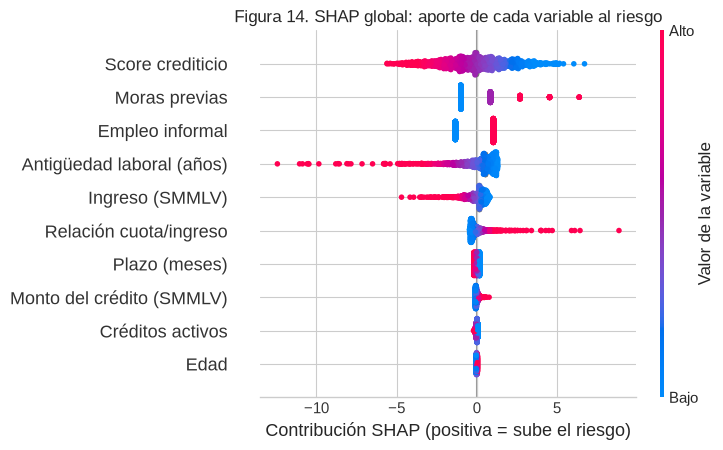

In [7]:
plt.figure()
shap.plots.beeswarm(sv, max_display=10, show=False, plot_size=(7.5, 4.6), color_bar_label="Valor de la variable")
plt.title("Figura 14. SHAP global: aporte de cada variable al riesgo")
plt.xlabel("Contribución SHAP (positiva = sube el riesgo)")
plt.tight_layout(); plt.savefig(FIGS / "fig14_shap_global.png", dpi=300, bbox_inches="tight"); plt.show()

## 3. SHAP local: tres solicitantes de la prueba
Se explican tres casos típicos: un moroso que el modelo **detecta**, un cliente formal que el modelo **aprueba**, y un
cliente informal que **sí paga pero el modelo rechaza** (el error más frecuente). Las barras muestran cuánto sube (rojo)
o baja (azul) cada variable el riesgo frente al solicitante promedio.

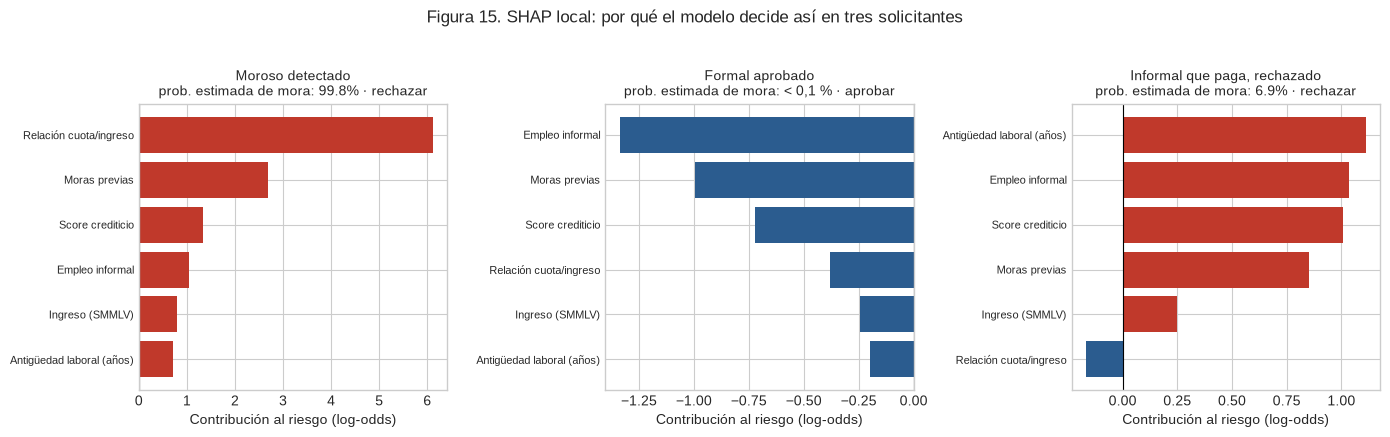

Caso,Moroso detectado,Formal aprobado,"Informal que paga, rechazado"
Edad,28.0,27.0,34.0
Empleo informal,1.0,0.0,1.0
Antigüedad laboral (años),1.6,4.1,0.5
Ingreso (SMMLV),0.55,3.22,1.94
Monto del crédito (SMMLV),9.09,1.94,2.84
Plazo (meses),12.0,36.0,24.0
Créditos activos,2.0,0.0,2.0
Moras previas,2.0,0.0,1.0
Score crediticio,570.0,653.0,583.0
Relación cuota/ingreso,1.653,0.02,0.073


In [8]:
p_test = modelo.predict_proba(X_test)[:, 1]
pred = (p_test >= UMBRAL).astype(int)
real = y_test.values
casos = {
    "Moroso detectado": np.where((real == 1) & (pred == 1))[0][np.argmax(p_test[(real == 1) & (pred == 1)])],
    "Formal aprobado": np.where((real == 0) & (pred == 0) & (X_test.es_informal.values == 0))[0][0],
    "Informal que paga, rechazado": np.where((real == 0) & (pred == 1))[0][np.argmin(p_test[(real == 0) & (pred == 1)] - UMBRAL)],
}

fig, axes = plt.subplots(1, 3, figsize=(14, 4.2), sharex=False)
filas = []
for ax, (titulo, i) in zip(axes, casos.items()):
    contrib = pd.Series(sv.values[i], index=sv.feature_names)
    top = contrib.reindex(contrib.abs().sort_values(ascending=False).index[:6])[::-1]
    ax.barh(top.index, top.values, color=np.where(top.values > 0, "#c0392b", "#2b5c8f"))
    ax.axvline(0, color="black", lw=0.8)
    pc = prob_corregida(p_test[i])
    texto_p = f"{pc:.1%}" if pc >= 0.001 else "< 0,1 %"
    ax.set_title(f"{titulo}\nprob. estimada de mora: {texto_p} · {'rechazar' if pred[i] else 'aprobar'}", fontsize=10)
    ax.set_xlabel("Contribución al riesgo (log-odds)")
    ax.tick_params(axis="y", labelsize=8)
    filas.append({"Caso": titulo, **{NOMBRES[c]: X_test.iloc[i][c] for c in X.columns},
                  "Prob. estimada de mora": round(pc, 4), "Real": "Incumple" if real[i] else "Al día"})
fig.suptitle("Figura 15. SHAP local: por qué el modelo decide así en tres solicitantes", y=1.03)
plt.tight_layout(); plt.savefig(FIGS / "fig15_shap_local.png", dpi=300, bbox_inches="tight"); plt.show()
pd.DataFrame(filas).set_index("Caso").T

## 4. Dependencia parcial (PDP) e ICE
La **dependencia parcial** muestra cómo cambia, en promedio, la probabilidad estimada de mora cuando una variable toma
distintos valores y las demás se dejan como están. Las líneas **ICE** (claras) muestran ese efecto solicitante por
solicitante. Se grafica la probabilidad corregida por la tasa real de mora (8,5 %, notebook 05).

*Cuidado:* la PDP mueve una variable sin mover las demás. Para `relacion_cuota_ingreso`, que se calcula con el monto, el
plazo y el ingreso, eso crea combinaciones que no ocurren en los datos; su curva se lee con esa precaución.

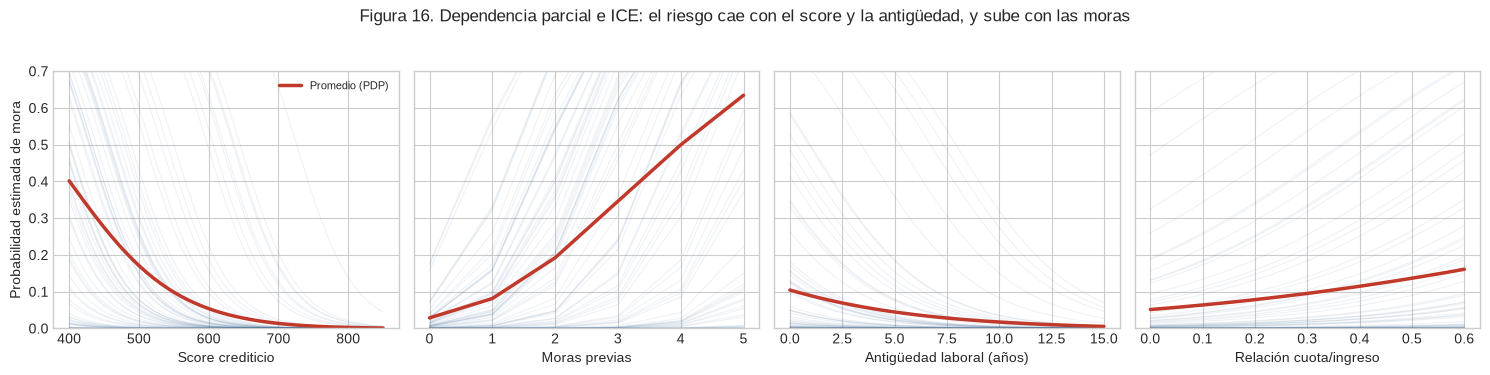

Score crediticio             de 40.2% a 0.1%
Moras previas                de 2.9% a 63.5%
Antigüedad laboral (años)    de 10.4% a 0.6%
Relación cuota/ingreso       de 5.1% a 16.1%


In [9]:
def dependencia(col, valores, base, n_ice=80):
    ice = []
    for v in valores:
        Xv = base.copy(); Xv[col] = v
        ice.append(prob_corregida(modelo.predict_proba(Xv)[:, 1]))
    ice = np.array(ice).T
    return ice.mean(0), ice[np.random.default_rng(SEED).choice(len(base), n_ice, replace=False)]

variables_pdp = {"score_crediticio": np.linspace(400, 850, 46), "moras_previas": np.arange(0, 6),
                 "antiguedad_laboral": np.linspace(0, 15, 31), "relacion_cuota_ingreso": np.linspace(0, 0.6, 31)}
fig, axes = plt.subplots(1, 4, figsize=(15, 3.6), sharey=True)
pdp_tabla = {}
for ax, (col, vals) in zip(axes, variables_pdp.items()):
    pdp, ice = dependencia(col, vals, X_test)
    ax.plot(vals, ice.T, color="#2b5c8f", alpha=0.08, lw=0.8)
    ax.plot(vals, pdp, color="#c0392b", lw=2.5, label="Promedio (PDP)")
    ax.set(xlabel=NOMBRES[col], ylim=(0, 0.7))
    pdp_tabla[NOMBRES[col]] = pd.Series(pdp, index=np.round(vals, 3))
axes[0].set_ylabel("Probabilidad estimada de mora")
axes[0].legend(fontsize=8, loc="upper right")
fig.suptitle("Figura 16. Dependencia parcial e ICE: el riesgo cae con el score y la antigüedad, y sube con las moras",
             y=1.03)
plt.tight_layout(); plt.savefig(FIGS / "fig16_dependencia_parcial.png", dpi=300, bbox_inches="tight"); plt.show()

for nombre, s in pdp_tabla.items():
    print(f"{nombre:28s} de {s.iloc[0]:.1%} a {s.iloc[-1]:.1%}")

### 4.1 El mismo efecto, por tipo de empleo
Como la simulación casi no tiene morosos formales, conviene ver la dependencia parcial del score por separado.

Informal score 500: 29.5% | score 600: 9.4% | score 700: 2.4%
Formal   score 500: 0.8% | score 600: 0.1% | score 700: 0.0%


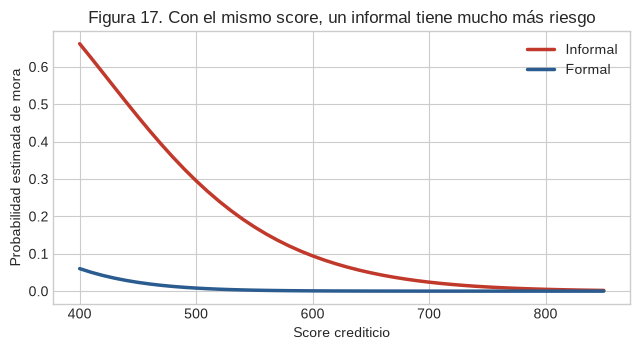

In [10]:
vals = variables_pdp["score_crediticio"]
fig, ax = plt.subplots(figsize=(6.5, 3.6))
for seg, color in [(1, "#c0392b"), (0, "#2b5c8f")]:
    pdp, _ = dependencia("score_crediticio", vals, X_test[X_test.es_informal == seg])
    ax.plot(vals, pdp, color=color, lw=2.5, label="Informal" if seg else "Formal")
    s_pdp = pd.Series(pdp, index=vals)
    print(f"{'Informal' if seg else 'Formal':8s} score 500: {s_pdp.loc[500]:.1%} | score 600: {s_pdp.loc[600]:.1%} | score 700: {s_pdp.loc[700]:.1%}")
ax.set(xlabel="Score crediticio", ylabel="Probabilidad estimada de mora",
       title="Figura 17. Con el mismo score, un informal tiene mucho más riesgo")
ax.legend()
plt.tight_layout(); plt.savefig(FIGS / "fig17_pdp_score_por_empleo.png", dpi=300); plt.show()

## 5. Tipos de error y sus implicaciones
Se compara el perfil promedio de los cuatro grupos de la matriz de confusión en la prueba (umbral del modelo final).

In [11]:
grupo = np.select([(real == 1) & (pred == 1), (real == 1) & (pred == 0), (real == 0) & (pred == 1)],
                  ["Moroso detectado (VP)", "Moroso no detectado (FN)", "Falsa alarma (FP)"], "Bien aprobado (VN)")
perfil = X_test.assign(Grupo=grupo, prob=prob_corregida(p_test)).groupby("Grupo").agg(
    Solicitantes=("edad", "size"), Informales=("es_informal", "mean"), Score=("score_crediticio", "mean"),
    Moras=("moras_previas", "mean"), Antigüedad=("antiguedad_laboral", "mean"), Ingreso=("ingreso_smmlv", "mean"),
    Cuota_ingreso=("relacion_cuota_ingreso", "mean"), Prob_estimada=("prob", "mean"))
perfil = perfil.loc[["Moroso detectado (VP)", "Moroso no detectado (FN)", "Falsa alarma (FP)", "Bien aprobado (VN)"]]
perfil.round(3).to_csv(TABLES / "tabla8_perfil_errores.csv")
perfil.round(3)

,Solicitantes,Informales,Score,Moras,Antigüedad,Ingreso,Cuota_ingreso,Prob_estimada
Grupo,,,,,,,,
Moroso detectado (VP),95,1.000,537.713,1.558,1.415,1.445,0.347,0.546
Moroso no detectado (FN),7,0.857,544.000,0.714,2.100,1.626,0.122,0.037
Falsa alarma (FP),150,1.000,542.866,1.100,1.660,1.818,0.160,0.227
Bien aprobado (VN),948,0.454,651.775,0.335,4.223,2.927,0.095,0.007


## 6. Lectura

**1. Qué sube y qué baja el riesgo (Figura 13).** Tres variables aumentan las odds de mora de forma estable: las moras
previas (×4,1 por cada desviación estándar; IC 95 %: 3,7–4,9), el empleo informal (×3,2; 2,8–3,8) y la relación
cuota/ingreso (×1,8; 1,5–2,2). Tres las reducen: el score crediticio (×0,13), la antigüedad laboral (×0,21) y el ingreso
(×0,54). La edad, el plazo, el monto y los créditos activos tienen intervalos que cruzan 1: el modelo no les atribuye un
efecto claro, lo que coincide con la simulación, donde no influyen en la mora.

**2. El modelo recupera la estructura de la simulación.** Los seis coeficientes del modelo tienen el mismo signo que los
de la fórmula de la mora y son proporcionales a ellos: todos son entre 3,0 y 3,7 veces mayores. El factor común se debe
a que la mora se asignó con un corte determinista (el 8,5 % de mayor riesgo) y no con un sorteo, lo que vuelve la
frontera más nítida. Que el modelo encuentre la estructura correcta valida el flujo; no dice nada todavía sobre datos reales.

**3. Qué pesa más en el conjunto (Figura 14).** Según SHAP, las variables con mayor aporte promedio son el score (1,69 en
log-odds), las moras previas (1,20), la informalidad (1,17) y la antigüedad (1,06), seguidas del ingreso y la relación
cuota/ingreso. Es el mismo grupo principal que en la importancia por permutación del notebook 03.

**4. Por qué decide así con personas concretas (Figura 15).**
- *Moroso detectado:* informal, gana 0,55 SMMLV y pidió 9,1 SMMLV a 12 meses, de modo que la cuota supera su ingreso
  (relación 1,65); además tiene 2 moras previas. Probabilidad estimada: 99,8 %.
- *Formal aprobado:* empleo formal, sin moras, score de 653 y una cuota del 2 % de su ingreso. Probabilidad < 0,1 %.
- *Informal que paga, rechazado:* lleva 6 meses en su trabajo, es informal, tiene score de 583 y una mora previa. Su
  cuota es baja (7 % del ingreso), pero no compensa lo demás: probabilidad de 6,9 %, apenas por encima del umbral (6,8 %).
  Es un caso límite.

**5. Cómo cambia el riesgo (Figuras 16 y 17).** Con todo lo demás igual, subir el score de 400 a 850 baja la
probabilidad estimada de mora de 40 % a 0,1 %; pasar de 0 a 5 moras previas la sube de 3 % a 64 %; y pasar de 0 a 15 años
de antigüedad la baja de 10 % a 0,6 %. La informalidad cambia la escala de todo: con un score de 500, un informal tiene
29,5 % de probabilidad y un formal 0,8 %; con 600, 9,4 % frente a 0,1 %.

**6. Tipos de error e implicaciones.** En la prueba hay dos tipos de error:
- *Morosos no detectados (7 de 102):* tienen un perfil más seguro que los demás morosos (0,7 moras previas frente a 1,6 y
  una cuota del 12 % del ingreso frente a 35 %). Su mora se explica por factores que el modelo no observa. Para el banco
  es la pérdida directa del crédito.
- *Falsas alarmas (150):* todas son de informales que pagan, con un perfil casi igual al de los morosos detectados
  (score de 543 frente a 538, 1,7 años de antigüedad). Con las variables disponibles no se pueden distinguir. Para la
  sociedad es el costo planteado desde la Primera entrega: excluir del crédito al 26 % de los informales que sí pagan.

*Implicaciones prácticas:* (a) el umbral debe fijarse según cuánto cuesta cada error para la entidad; (b) los casos
cercanos al umbral, como el tercer solicitante, deberían pasar a revisión humana en vez de rechazarse automáticamente;
(c) para los informales hacen falta datos alternativos (pagos de servicios, ingresos por transferencias) que distingan a
quienes pagan de quienes no.

**7. Alcance de estas conclusiones.** Las explicaciones describen cómo decide el modelo, no relaciones causales: que el
score baje el riesgo en el modelo no significa que subir el score de una persona reduzca su mora. Además, como los datos
son simulados, el modelo reproduce los supuestos de la simulación (por ejemplo, la mora formal casi nula). Antes de usarlo
para decisiones reales habría que validarlo con datos reales.